In [1]:
RUN_FINAL = False

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import mlflow

print(sys.executable)
print(Path.cwd())
assert (Path.cwd() / "pyproject.toml").is_file()

d:\campaign-mini\.venv\Scripts\python.exe
d:\campaign-mini


In [2]:
from pathlib import Path
import mlflow
from mlflow import MlflowClient

from tracking import configure_tracking

context = configure_tracking()
experiment_name = "campaign-mini"

experiment = mlflow.get_experiment_by_name(experiment_name)

if experiment is None:
    experiment_id = mlflow.create_experiment(
        experiment_name,
        artifact_location=context["artifact_uri"],
    )
else:
    if experiment.lifecycle_stage != "active":
        raise ValueError("The existing experiment is not active")

    if (
        experiment.artifact_location.rstrip("/")
        != context["artifact_uri"].rstrip("/")
    ):
        raise ValueError(
            "The existing experiment uses a different artifact location"
        )

    experiment_id = experiment.experiment_id

mlflow.set_experiment(experiment_id=experiment_id)

print("Experiment:", experiment_name)
print("Tracking URI:", context["tracking_uri"])
print("Artifact location:", context["artifact_uri"])

Experiment: campaign-mini
Tracking URI: sqlite:///C:/Users/KISHAN PRAJAPATI/AppData/Local/campaign-mini-state/mlflow.db
Artifact location: file:///C:/Users/KISHAN%20PRAJAPATI/AppData/Local/campaign-mini-state/artifacts


In [3]:
with mlflow.start_run(
    run_name="setup-check",
    tags={"purpose": "setup_check"},
) as run:
    mlflow.log_param("check_kind", "round_trip")
    mlflow.log_metric("check_value", 1.0)
    mlflow.log_text(
        "Tracking round-trip succeeded.",
        "setup_note.txt",
    )

run_id = run.info.run_id

print("Saved run ID:", run_id)

Saved run ID: b2734f68205349db96b5eea0edcf6790


In [4]:
client = MlflowClient(tracking_uri=context["tracking_uri"])
saved = client.get_run(run_id)
note_path = client.download_artifacts(run_id, "setup_note.txt")
note_text = Path(note_path).read_text(encoding="utf-8")

assert saved.info.status == "FINISHED"
assert saved.data.params["check_kind"] == "round_trip"
assert saved.data.metrics["check_value"] == 1.0
assert saved.data.tags["purpose"] == "setup_check"
assert note_text == "Tracking round-trip succeeded."

print("Run ID:", run_id)
print("Status:", saved.info.status)
print("Parameter:", saved.data.params["check_kind"])
print("Metric:", saved.data.metrics["check_value"])
print("Tag:", saved.data.tags["purpose"])
print("Artifact:", note_text)
print("All setup checks passed.")

Run ID: b2734f68205349db96b5eea0edcf6790
Status: FINISHED
Parameter: round_trip
Metric: 1.0
Tag: setup_check
Artifact: Tracking round-trip succeeded.
All setup checks passed.


In [5]:
import hashlib

ROOT = Path.cwd()
assert (ROOT / "pyproject.toml").is_file(), "Open the campaign-mini folder"

if (ROOT / "results/final_result.json").exists():
    raise RuntimeError(
        "Final access already started; use the recorded results"
    )

for folder in ["data/raw", "data/holdout", "results/figures"]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

RAW = ROOT / "data/raw/bank-additional-full.csv"

NUMERIC = ["age", "previous"]
CATEGORICAL = [
    "job", "marital", "education", "housing", "loan", "poutcome"
]
FEATURES = NUMERIC + CATEGORICAL

In [6]:
assert RAW.is_file(), f"Place the downloaded CSV at {RAW}"

source_sha256 = hashlib.sha256(RAW.read_bytes()).hexdigest()
source = pd.read_csv(
    RAW,
    sep=";",
    keep_default_na=False,
    dtype="string",
)

assert len(source) == 41188, "Check the dataset variant"

missing = set(FEATURES + ["y"]) - set(source.columns)
assert not missing, f"Missing columns: {missing}"
for column in FEATURES + ["y"]:
    source[column] = source[column].str.strip().replace("", pd.NA)

assert source["y"].isin(["yes", "no"]).all(), "Invalid or missing target"

for column in NUMERIC:
    source[column] = pd.to_numeric(
        source[column], errors="raise"
    ).astype("float64")

    values = source[column].dropna()
    assert np.isfinite(values).all(), f"Infinite values in {column}"
    assert (values >= 0).all(), f"Negative values in {column}"

source.insert(0, "record_id", range(len(source)))

print("Source SHA-256:", source_sha256)
print("Source rows:", len(source))

Source SHA-256: 74adfc578bf77a7ff4bb1ba4a9f8709d9e3c6907342959c2c8416847e0afb4d8
Source rows: 41188


In [7]:
from sklearn.model_selection import train_test_split

n = len(source)
train_size = 7 * n // 10
dev_size = 85 * n // 100 - train_size

train, remaining = train_test_split(
    source,
    train_size=train_size,
    shuffle=False,
)

dev, final = train_test_split(
    remaining,
    train_size=dev_size,
    shuffle=False,
)

del remaining

assert (len(train), len(dev), len(final)) == (28831, 6178, 6179)

split_ids = pd.concat(
    [
        train[["record_id"]].assign(split="train"),
        dev[["record_id"]].assign(split="dev"),
        final[["record_id"]].assign(split="final"),
    ],
    ignore_index=True,
)

assert split_ids["record_id"].is_unique

pd.testing.assert_series_equal(
    split_ids["record_id"],
    source["record_id"].reset_index(drop=True),
)

split_ids.to_csv(ROOT / "data/split_ids.csv", index=False)

print(split_ids["split"].value_counts(sort=False))

split
train    28831
dev       6178
final     6179
Name: count, dtype: int64


In [8]:
final[["record_id"] + FEATURES].to_csv(
    ROOT / "data/holdout/final_features.csv",
    index=False,
)

final_labels = final[["record_id", "y"]].copy()
final_labels["y"] = (
    final_labels["y"]
    .map({"no": 0, "yes": 1})
    .astype("int64")
)

final_labels.to_csv(
    ROOT / "data/holdout/final_labels.csv",
    index=False,
)
assert hashlib.sha256(RAW.read_bytes()).hexdigest() == source_sha256

del final_labels, final, source

print("Final files saved. Continue exploration with train only.")

Final files saved. Continue exploration with train only.


In [9]:
train_y = train["y"].map({"no": 0, "yes": 1}).astype("int64")

numeric_summary = train[NUMERIC].describe().T

unknown_counts = train[CATEGORICAL].eq("unknown").sum()

category_summary = pd.DataFrame({
    "unknown_count": unknown_counts,
    "unknown_pct": 100 * unknown_counts / len(train),
    "missing_count": train[CATEGORICAL].isna().sum(),
})

outcome_summary = (
    train.assign(subscribed=train_y)
    .groupby("poutcome", dropna=False)
    .agg(
        records=("subscribed", "size"),
        subscribers=("subscribed", "sum"),
        subscription_rate=("subscribed", "mean"),
    )
)

print(numeric_summary)
print(category_summary)
print(outcome_summary)

            count       mean       std   min   25%   50%   75%   max
age       28831.0  40.177483  9.335439  18.0  33.0  39.0  47.0  95.0
previous  28831.0   0.035899  0.192456   0.0   0.0   0.0   0.0   3.0
           unknown_count  unknown_pct  missing_count
job                  249     0.863654              0
marital               49     0.169956              0
education           1183     4.103222              0
housing              694     2.407131              0
loan                 694     2.407131              0
poutcome               0          0.0              0
             records  subscribers  subscription_rate
poutcome                                            
failure          952           56           0.058824
nonexistent    27829         1543           0.055446
success           50            7           0.140000


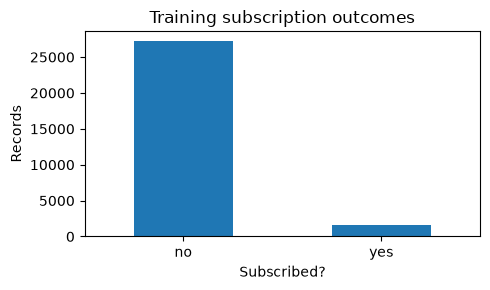

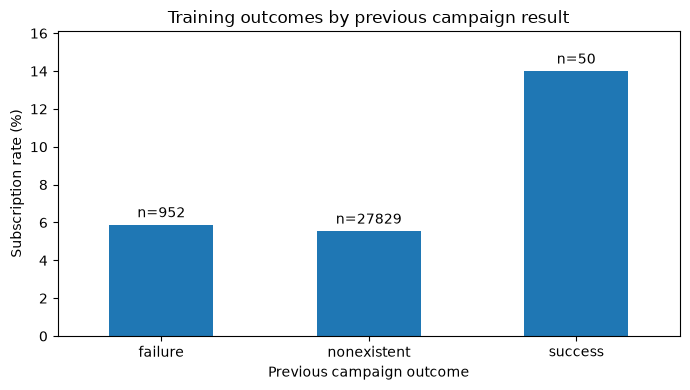

In [10]:
class_counts = (
    train["y"]
    .value_counts()
    .reindex(["no", "yes"], fill_value=0)
)
fig, ax = plt.subplots(figsize=(5, 3))
class_counts.plot.bar(ax=ax, rot=0)

ax.set(
    title="Training subscription outcomes",
    xlabel="Subscribed?",
    ylabel="Records",
)

fig.tight_layout()
fig.savefig(
    ROOT / "results/figures/train_class_counts.png",
    dpi=150,
)
plt.show()
plt.close(fig)


fig, ax = plt.subplots(figsize=(7, 4))

(100 * outcome_summary["subscription_rate"]).plot.bar(
    ax=ax,
    rot=0,
)

ax.bar_label(
    ax.containers[0],
    labels="n=" + outcome_summary["records"].astype(str),
    padding=3,
)
ax.margins(y=0.15)

ax.set(
    title="Training outcomes by previous campaign result",
    xlabel="Previous campaign outcome",
    ylabel="Subscription rate (%)",
)

fig.tight_layout()
fig.savefig(
    ROOT / "results/figures/train_poutcome_rate.png",
    dpi=150,
)
plt.show()
plt.close(fig)

In [11]:
from helpers import FEATURES, prepare_inputs

train_ids, X_train, y_train = prepare_inputs(train, mode="labeled")
dev_ids, X_dev, y_dev = prepare_inputs(dev, mode="labeled")

assert len(train_ids) == len(X_train) == len(y_train)
assert len(dev_ids) == len(X_dev) == len(y_dev)
assert X_train.columns.tolist() == FEATURES
assert X_dev.columns.tolist() == FEATURES

print("Training inputs:", X_train.shape)
print("Development inputs:", X_dev.shape)
print("Training target values:", y_train.unique())

Training inputs: (28831, 8)
Development inputs: (6178, 8)
Training target values: [0 1]


In [12]:
import importlib

import numpy as np
import pandas as pd

import helpers

importlib.reload(helpers)
from helpers import FEATURES, NUMERIC, build_pipeline, prepare_inputs

In [13]:
for original, ids, X, y in [
    (train, train_ids, X_train, y_train),
    (dev, dev_ids, X_dev, y_dev),
]:
    assert len(original) == len(ids) == len(X) == len(y)
    assert list(X.columns) == FEATURES
    assert ids.index.equals(original.index)
    assert ids.index.equals(X.index) and X.index.equals(y.index)
    assert ids.tolist() == original['record_id'].tolist()
    assert not {'record_id', 'y'} & set(X.columns)

assert not train_ids.isin(dev_ids).any()
print('Train shape:', X_train.shape, 'Development shape:', X_dev.shape)
print(pd.DataFrame({
    'dtype': X_train.dtypes.astype(str),
    'missing_in_train': X_train.isna().sum(),
}))

Train shape: (28831, 8) Development shape: (6178, 8)
             dtype  missing_in_train
age        float64                 0
previous   float64                 0
job         object                 0
marital     object                 0
education   object                 0
housing     object                 0
loan        object                 0
poutcome    object                 0


In [14]:
toy = pd.DataFrame({
    'record_id': [0, 1, 2, 3],
    'age': [20, 40, np.nan, 60],
    'previous': [0, 1, 2, 3],
    'job': ['admin.', 'technician', None, 'admin.'],
    'marital': ['single', 'married', 'single', 'married'],
    'education': ['high.school', 'university.degree', 'high.school', 'high.school'],
    'housing': ['yes', 'no', 'yes', 'no'],
    'loan': ['no', 'no', 'yes', 'no'],
    'poutcome': ['nonexistent', 'failure', 'success', 'nonexistent'],
    'y': ['no', 'yes', 'no', 'yes'],
})
_, X_toy, y_toy = prepare_inputs(toy, mode='labeled')
demo_model = build_pipeline('lr_c1')
demo_model.fit(X_toy, y_toy)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prepare', ...), ('classify', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['age','previous','job',...,'housing','loan','poutcome']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns t

In [15]:
prep = demo_model.named_steps['prepare']
num = prep.named_transformers_['num']
imputer = num.named_steps['impute']
scaler = num.named_steps['scale']
encoder = prep.named_transformers_['cat'].named_steps['encode']

expected_medians = X_toy[NUMERIC].median()
filled = X_toy[NUMERIC].fillna(expected_medians)
np.testing.assert_allclose(imputer.statistics_, expected_medians)
np.testing.assert_allclose(scaler.mean_, filled.mean())
np.testing.assert_allclose(scaler.var_, filled.var(ddof=0))

print(pd.DataFrame({
    'median': imputer.statistics_,
    'mean_after_imputation': scaler.mean_,
    'variance_after_imputation': scaler.var_,
    'scale': scaler.scale_,
}, index=NUMERIC))
print('Learned category lists:', encoder.categories_)
transformed = prep.transform(X_toy)
print('Transformed shape:', transformed.shape)
print('Transformed names:', prep.get_feature_names_out())
assert transformed.shape[1] == len(prep.get_feature_names_out())

          median  mean_after_imputation  variance_after_imputation      scale
age         40.0                   40.0                     200.00  14.142136
previous     1.5                    1.5                       1.25   1.118034
Learned category lists: [array(['admin.', 'technician', 'unknown'], dtype=object), array(['married', 'single'], dtype=object), array(['high.school', 'university.degree'], dtype=object), array(['no', 'yes'], dtype=object), array(['no', 'yes'], dtype=object), array(['failure', 'nonexistent', 'success'], dtype=object)]
Transformed shape: (4, 16)
Transformed names: ['num__age' 'num__previous' 'cat__job_admin.' 'cat__job_technician'
 'cat__job_unknown' 'cat__marital_married' 'cat__marital_single'
 'cat__education_high.school' 'cat__education_university.degree'
 'cat__housing_no' 'cat__housing_yes' 'cat__loan_no' 'cat__loan_yes'
 'cat__poutcome_failure' 'cat__poutcome_nonexistent'
 'cat__poutcome_success']


In [16]:
future_toy = toy.iloc[[0]].drop(columns='y').assign(
    record_id=99, age=1_000_000, job='new_job',
)
_, X_future_toy, _ = prepare_inputs(future_toy, mode='predict')
statistics_before = [
    imputer.statistics_.copy(), scaler.mean_.copy(), scaler.var_.copy(),
]
probabilities = demo_model.predict_proba(X_future_toy)
print('Toy classes:', demo_model.classes_)
print('Toy probabilities:', probabilities)
assert np.isfinite(probabilities).all()
for actual, expected in zip(
    [imputer.statistics_, scaler.mean_, scaler.var_], statistics_before,
):
    np.testing.assert_allclose(actual, expected)
np.testing.assert_allclose(
    probabilities,
    demo_model.predict_proba(X_future_toy.loc[:, FEATURES[::-1]]),
)
print('Toy boundary checks passed.')

Toy classes: [0 1]
Toy probabilities: [[0. 1.]]
Toy boundary checks passed.


In [17]:
import helpers

importlib.reload(helpers)
from helpers import evaluate_ranking, positive_scores, rank_customers

In [18]:
from scipy.special import expit
X_math = np.array([[0, 1], [1, 0], [1, 1]], dtype=float)
y_math = np.array([0, 1, 1], dtype=float)
w_math = np.zeros(2, dtype=float)
b_math = 0.0

z = X_math @ w_math + b_math
p = expit(z)
loss = np.mean(np.logaddexp(0, z) - y_math * z)
dw = X_math.T @ (p - y_math) / len(X_math)
db = np.mean(p - y_math)
print('Initial logits:', z, 'probabilities:', p)
print('Initial loss:', loss, 'dw:', dw, 'db:', db)
np.testing.assert_allclose(loss, np.log(2))
np.testing.assert_allclose(dw, [-1 / 3, 0], atol=1e-12)
np.testing.assert_allclose(db, -1 / 6)

Initial logits: [0. 0. 0.] probabilities: [0.5 0.5 0.5]
Initial loss: 0.6931471805599453 dw: [-0.33333333  0.        ] db: -0.16666666666666666


In [19]:
theta = np.r_[w_math, b_math]
epsilon = 1e-5
numerical_gradient = np.empty_like(theta)
for index in range(len(theta)):
    offset = np.zeros_like(theta)
    offset[index] = epsilon
    plus, minus = theta + offset, theta - offset
    z_plus = X_math @ plus[:-1] + plus[-1]
    z_minus = X_math @ minus[:-1] + minus[-1]
    loss_plus = np.mean(np.logaddexp(0, z_plus) - y_math * z_plus)
    loss_minus = np.mean(np.logaddexp(0, z_minus) - y_math * z_minus)
    numerical_gradient[index] = (loss_plus - loss_minus) / (2 * epsilon)

analytic_gradient = np.r_[dw, db]
np.testing.assert_allclose(analytic_gradient, numerical_gradient, rtol=1e-5, atol=1e-8)
print(pd.DataFrame({
    'analytic': analytic_gradient, 'finite_difference': numerical_gradient,
}, index=['w0', 'w1', 'b']))

    analytic  finite_difference
w0 -0.333333          -0.333333
w1  0.000000           0.000000
b  -0.166667          -0.166667


In [20]:
updates = []
for learning_rate in [0.1, 100]:
    next_w = w_math - learning_rate * dw
    next_b = b_math - learning_rate * db
    next_z = X_math @ next_w + next_b
    next_loss = np.mean(np.logaddexp(0, next_z) - y_math * next_z)
    updates.append({
        'learning_rate': learning_rate, 'loss_before': loss,
        'loss_after': float(next_loss), 'first_row_probability': float(expit(next_z[0])),
    })
print(pd.DataFrame(updates))
assert updates[0]['loss_after'] < loss < updates[1]['loss_after']

   learning_rate  loss_before  loss_after  first_row_probability
0            0.1     0.693147    0.679478               0.504167
1          100.0     0.693147    5.555556               1.000000


In [21]:
extreme_z = np.array([-1000.0, 1000.0])
extreme_y = np.array([1.0, 0.0])
with np.errstate(over='raise', invalid='raise'):
    extreme_p = expit(extreme_z)
    extreme_loss = np.mean(np.logaddexp(0, extreme_z) - extreme_y * extreme_z)
assert np.isfinite(extreme_p).all() and np.isfinite(extreme_loss)
np.testing.assert_allclose(extreme_loss, 1000)
print('Extreme logits:', extreme_z, 'probabilities:', extreme_p, 'loss:', extreme_loss)

Extreme logits: [-1000.  1000.] probabilities: [0. 1.] loss: 1000.0


In [22]:
import json
policy = {
    'budget_numerator': 1,
    'budget_denominator': 10,
    'tie_break': 'record_id_ascending',
}
fixture_ids = np.arange(20)
fixture_probabilities = (20 - fixture_ids) / 21
fixture_labels = pd.DataFrame({
    'record_id': fixture_ids,
    'y': np.isin(fixture_ids, [0, 1, 10, 11]).astype(int),
})
fixture_ranked = rank_customers(fixture_ids, fixture_probabilities, policy)
fixture_metrics = evaluate_ranking(fixture_ids, fixture_probabilities, fixture_labels, policy)
print(fixture_ranked)
print(json.dumps(fixture_metrics, indent=2, allow_nan=False))
assert fixture_ranked.loc[fixture_ranked['selected'], 'record_id'].tolist() == [0, 1]
assert fixture_metrics['precision_at_budget'] == 1
assert fixture_metrics['recall_at_budget'] == .5
assert fixture_metrics['lift'] == 5

    record_id  estimated_probability  rank  selected
0           0               0.952381     1      True
1           1               0.904762     2      True
2           2               0.857143     3     False
3           3               0.809524     4     False
4           4               0.761905     5     False
5           5               0.714286     6     False
6           6               0.666667     7     False
7           7               0.619048     8     False
8           8               0.571429     9     False
9           9               0.523810    10     False
10         10               0.476190    11     False
11         11               0.428571    12     False
12         12               0.380952    13     False
13         13               0.333333    14     False
14         14               0.285714    15     False
15         15               0.238095    16     False
16         16               0.190476    17     False
17         17               0.142857    18    

In [23]:
shuffled_labels = fixture_labels.sample(frac=1, random_state=7).reset_index(drop=True)
assert evaluate_ranking(fixture_ids, fixture_probabilities, shuffled_labels, policy) == fixture_metrics
print('Independent label reordering preserved the result.')

Independent label reordering preserved the result.


In [24]:
small_metrics = evaluate_ranking(
    fixture_ids[:9], fixture_probabilities[:9], fixture_labels.iloc[:9], policy,
)
zero_metrics = evaluate_ranking(
    fixture_ids, fixture_probabilities, fixture_labels.assign(y=0), policy,
)
print('Nine row batch:', json.dumps(small_metrics, indent=2, allow_nan=False))
print('Zero positive batch:', json.dumps(zero_metrics, indent=2, allow_nan=False))
assert small_metrics['precision_at_budget'] is None
assert zero_metrics['ap'] is None
print('notebook assertions passed')

Nine row batch: {
  "n": 9,
  "k": 0,
  "positives": 2,
  "tp": 0,
  "fp": 0,
  "fn": 2,
  "tn": 7,
  "precision_at_budget": null,
  "recall_at_budget": 0.0,
  "lift": null,
  "ap": 1.0,
  "brier": 0.4051398337112623,
  "log_loss": 1.0390944874743167,
  "undefined": {
    "precision_at_budget": "k=0: no records selected",
    "lift": "Lift requires k>0 and P>0"
  },
  "random_reference": {
    "expected_tp": 0.0,
    "expected_precision": null,
    "expected_recall": 0.0,
    "expected_lift": null,
    "undefined": {
      "expected_precision": "k=0: precision is undefined",
      "expected_lift": "Lift requires k>0 and P>0"
    }
  }
}
Zero positive batch: {
  "n": 20,
  "k": 2,
  "positives": 0,
  "tp": 0,
  "fp": 2,
  "fn": 0,
  "tn": 18,
  "precision_at_budget": 0.0,
  "recall_at_budget": null,
  "lift": null,
  "ap": null,
  "brier": 0.3253968253968254,
  "log_loss": 0.9277416146857487,
  "undefined": {
    "recall_at_budget": "P=0: no positive labels",
    "ap": "P=0: no positive

In [25]:
import json
import os
import warnings
from pathlib import Path
import mlflow
import numpy as np
import pandas as pd
from IPython.display import display
from mlflow.artifacts import load_dict
from mlflow.tracking import MlflowClient
from sklearn.exceptions import ConvergenceWarning
from helpers import FEATURES, build_pipeline, evaluate_ranking, positive_scores

project_root = Path.cwd()
if not (project_root / "pyproject.toml").is_file():
    raise RuntimeError("Open the notebook from your campaign-mini project root.")
results_dir = project_root / "results"
if any((results_dir / name).exists() for name in ("final_access.json", "final_result.json")):
    raise RuntimeError("Final access was already recorded. Bypass E-H and inspect the saved result.")
if mlflow.active_run() is not None or os.environ.get("MLFLOW_RUN_ID"):
    raise RuntimeError("An MLflow run is already active/resumable. Resolve it before creating candidates.")

assert list(X_train.columns) == list(X_dev.columns) == FEATURES
assert len(train_ids) == len(X_train) == len(y_train) > 0
assert len(dev_ids) == len(X_dev) == len(y_dev) > 0
assert train_ids.index.equals(X_train.index) and y_train.index.equals(X_train.index)
assert dev_ids.index.equals(X_dev.index) and y_dev.index.equals(X_dev.index)
assert set(y_train.unique()) == {0, 1}, "Training requires both classes."
assert y_dev.isin([0, 1]).all()
assert train_ids.is_unique and dev_ids.is_unique
assert train_ids.max() < dev_ids.min(), "Keep the ordered, disjoint split from B."

In [26]:
policy = {
    "budget_numerator": 1,
    "budget_denominator": 10,
    "tie_break": "record_id_ascending",
}
dev_labels = pd.DataFrame({"record_id": dev_ids.to_numpy(), "y": y_dev.to_numpy()})
n_dev, positives_dev = len(y_dev), int(y_dev.sum())
k_dev = n_dev // 10

tracking_uri = mlflow.get_tracking_uri() 
client = MlflowClient(tracking_uri=tracking_uri)
experiment = client.get_experiment_by_name("campaign-mini")
if experiment is None or experiment.lifecycle_stage != "active":
    raise RuntimeError("Return to A's existing tracking setup; do not create a replacement store.")
print("Tracking:", tracking_uri)
print("Experiment:", experiment.name, experiment.experiment_id)
print("Artifacts:", experiment.artifact_location)
print(f"Train={len(y_train)}, development={n_dev}, positives={positives_dev}, budget={k_dev}")
results_dir.mkdir(parents=True, exist_ok=True)

Tracking: sqlite:///C:/Users/KISHAN PRAJAPATI/AppData/Local/campaign-mini-state/mlflow.db
Experiment: campaign-mini 1
Artifacts: file:///C:/Users/KISHAN%20PRAJAPATI/AppData/Local/campaign-mini-state/artifacts
Train=28831, development=6178, positives=658, budget=617


In [27]:
candidate_ids = ["lr_c1", "prior", "lr_c01", "rf_d8"]
metric_names = [
    "n", "k", "positives", "tp", "fp", "fn", "tn",
    "precision_at_budget", "recall_at_budget", "lift", "ap", "brier", "log_loss",
]
candidates = {}
comparison_rows = []

for candidate_id in candidate_ids:
    run_id = None
    phase = "start_run"
    try:
        with mlflow.start_run(
            experiment_id=experiment.experiment_id,
            run_name=candidate_id,
            tags={"purpose": "candidate", "candidate_id": candidate_id},
        ) as run:
            run_id = run.info.run_id
            phase = "configure_and_log_parameters"
            model = build_pipeline(candidate_id)
            classifier = model.named_steps["classify"]
            mlflow.log_params({
                "candidate_id": candidate_id,
                "classifier": type(classifier).__name__,
                "train_n": len(y_train),
                "dev_n": n_dev,
                **classifier.get_params(deep=False),
            }, synchronous=True)
            mlflow.log_dict({"features": FEATURES, "policy": policy}, "input_contract.json")

            phase = "fit"
            with warnings.catch_warnings():
                warnings.simplefilter("error", ConvergenceWarning)
                model.fit(X_train, y_train)

            phase = "development_evaluation"
            dev_probabilities = positive_scores(model, X_dev)
            metrics = evaluate_ranking(dev_ids, dev_probabilities, dev_labels, policy)
            json.dumps(metrics, allow_nan=False)

            phase = "log_development_results"
            finite_metrics = {
                f"dev_{name}": value for name, value in metrics.items()
                if isinstance(value, (int, float)) and np.isfinite(value)
            }
            mlflow.log_metrics(finite_metrics, synchronous=True)
            mlflow.log_dict(metrics, "development_metrics.json")
            phase = "close_run"

        entry = {
            "candidate_id": candidate_id, "pipeline": model, "run_id": run_id,
            "status": "success", "dev_scores": dev_probabilities,
            "metrics": metrics, "failure_reason": "",
        }
    except Exception as exc:
        reason = f"{phase}: {type(exc).__name__}: {exc}"
        entry = {
            "candidate_id": candidate_id, "pipeline": None, "run_id": run_id,
            "status": "failed", "dev_scores": None,
            "metrics": None, "failure_reason": reason,
        }
        print(candidate_id, "FAILED:", reason)

    candidates[candidate_id] = entry
    record = entry["metrics"]
    row = {name: record[name] if record is not None else None for name in metric_names}
    row.update({
        "candidate_id": candidate_id, "run_id": run_id, "status": entry["status"],
        "n": n_dev, "k": k_dev, "positives": positives_dev,
        "failure_reason": entry["failure_reason"],
        "undefined_reason": json.dumps(record["undefined"] if record is not None else {}),
    })
    comparison_rows.append(row)
    print(candidate_id, entry["status"], run_id)

lr_c1 success 8786f26b22844c189acf1663ffe90a2b
prior success 301cb87abae5472a9a26ab65bdf81cc8
lr_c01 success 6675bf04bb204594824df0ce32f2a6a3
rf_d8 success c2846f42f8f144f0b500f96d4c23d56a


In [28]:
comparison = pd.DataFrame(comparison_rows)
assert comparison["candidate_id"].tolist() == candidate_ids
assert comparison["candidate_id"].is_unique
comparison.to_csv(results_dir / "comparison.csv", index=False)
display(comparison)

random_reference = {
    "expected_tp": k_dev * positives_dev / n_dev,
    "expected_precision": positives_dev / n_dev if k_dev else None,
    "expected_recall": k_dev / n_dev if positives_dev else None,
    "expected_lift": 1.0 if k_dev and positives_dev else None,
}
print("Random shortlist expectation (not a fitted fifth candidate):")
display(pd.DataFrame([random_reference]))

,n,k,positives,tp,fp,fn,tn,precision_at_budget,recall_at_budget,lift,ap,brier,log_loss,candidate_id,run_id,status,failure_reason,undefined_reason
0,6178,617,658,143,474,515,5046,0.231767,0.217325,2.176070,0.162378,0.095881,0.346996,lr_c1,8786f26b22844c189acf1663ffe90a2b,success,,{}
1,6178,617,658,54,563,604,4957,0.087520,0.082067,0.821733,0.106507,0.097744,0.358772,prior,301cb87abae5472a9a26ab65bdf81cc8,success,,{}
2,6178,617,658,137,480,521,5040,0.222042,0.208207,2.084766,0.162821,0.096311,0.348997,lr_c01,6675bf04bb204594824df0ce32f2a6a3,success,,{}
3,6178,617,658,151,466,507,5054,0.244733,0.229483,2.297808,0.182712,0.095535,0.345213,rf_d8,c2846f42f8f144f0b500f96d4c23d56a,success,,{}


Random shortlist expectation (not a fitted fifth candidate):


,expected_tp,expected_precision,expected_recall,expected_lift
0,65.714794,0.106507,0.099871,1.0


In [29]:
run_checks = []
for candidate_id, entry in candidates.items():
    if entry["run_id"] is None:
        raise RuntimeError(f"{candidate_id} has no run ID. Repair tracking before continuing.")
    saved = client.get_run(entry["run_id"])
    expected_status = "FINISHED" if entry["status"] == "success" else "FAILED"
    assert saved.info.status == expected_status
    assert saved.info.experiment_id == experiment.experiment_id
    assert saved.data.tags["purpose"] == "candidate"
    assert saved.data.tags["candidate_id"] == candidate_id
    run_checks.append({"candidate_id": candidate_id, "run_id": entry["run_id"],
                       "mlflow_status": saved.info.status})
display(pd.DataFrame(run_checks))

successful = [entry for entry in candidates.values() if entry["status"] == "success"]
if not successful:
    raise RuntimeError("No successful candidate. Read failure_reason and diagnose before continuing.")
checked = successful[0]
saved = client.get_run(checked["run_id"])
assert saved.data.params["candidate_id"] == checked["candidate_id"]
assert saved.data.params["train_n"] == str(len(y_train))
assert saved.data.metrics["dev_n"] == n_dev
retrieved_metrics = load_dict(f"runs:/{checked['run_id']}/development_metrics.json")
assert retrieved_metrics == checked["metrics"]
print("Retrieved complete development metric record for", checked["candidate_id"], checked["run_id"])
print("Keep candidates and comparison in memory. No winner is chosen")

,candidate_id,run_id,mlflow_status
0,lr_c1,8786f26b22844c189acf1663ffe90a2b,FINISHED
1,prior,301cb87abae5472a9a26ab65bdf81cc8,FINISHED
2,lr_c01,6675bf04bb204594824df0ce32f2a6a3,FINISHED
3,rf_d8,c2846f42f8f144f0b500f96d4c23d56a,FINISHED


Retrieved complete development metric record for lr_c1 8786f26b22844c189acf1663ffe90a2b
Keep candidates and comparison in memory. No winner is chosen


In [30]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import TimeSeriesSplit, cross_validate, learning_curve

from helpers import FEATURES, build_pipeline

f_root = Path.cwd()
if not (f_root / "pyproject.toml").is_file():
    raise RuntimeError("Open the notebook from your campaign-mini project root.")
f_results = f_root / "results"
if any((f_results / name).exists() for name in ("final_access.json", "final_result.json")):
    raise RuntimeError("Final access was already recorded.")
assert list(X_train.columns) == FEATURES
assert len(train_ids) == len(X_train) == len(y_train) >= 4
assert train_ids.index.equals(X_train.index) and y_train.index.equals(X_train.index)
assert train_ids.is_unique and train_ids.is_monotonic_increasing
assert y_train.isin([0, 1]).all()
f_results.mkdir(parents=True, exist_ok=True)
(f_results / "figures").mkdir(parents=True, exist_ok=True)

In [31]:
f_splits = list(TimeSeriesSplit(n_splits=3).split(X_train))
fold_rows, supported_splits, supported_fold_ids = [], [], []

for fold_id, (fit_idx, valid_idx) in enumerate(f_splits, start=1):
    fit_labels = y_train.iloc[fit_idx]
    valid_labels = y_train.iloc[valid_idx]
    reasons = []
    if fit_labels.nunique() != 2:
        reasons.append("training prefix does not contain both labels")
    if int(valid_labels.sum()) == 0:
        reasons.append("validation window has no positives: AP is undefined here")
    fold_rows.append({
        "fold": fold_id,
        "train_id_start": int(train_ids.iloc[fit_idx[0]]),
        "train_id_end": int(train_ids.iloc[fit_idx[-1]]),
        "train_n": len(fit_idx), "train_positives": int(fit_labels.sum()),
        "train_negatives": int((fit_labels == 0).sum()),
        "train_rate": float(fit_labels.mean()),
        "valid_id_start": int(train_ids.iloc[valid_idx[0]]),
        "valid_id_end": int(train_ids.iloc[valid_idx[-1]]),
        "valid_n": len(valid_idx), "valid_positives": int(valid_labels.sum()),
        "valid_negatives": int((valid_labels == 0).sum()),
        "valid_rate": float(valid_labels.mean()),
        "status": "unsupported" if reasons else "supported",
        "reason": "; ".join(reasons),
    })
    if not reasons:
        supported_splits.append((fit_idx, valid_idx))
        supported_fold_ids.append(fold_id)

fold_table = pd.DataFrame(fold_rows).set_index("fold")
fold_table["train_ap"] = np.nan
fold_table["valid_ap"] = np.nan
fold_table.to_csv(f_results / "fold_diagnostics.csv", index_label="fold")
display(fold_table)

,train_id_start,train_id_end,train_n,train_positives,train_negatives,train_rate,valid_id_start,valid_id_end,valid_n,valid_positives,valid_negatives,valid_rate,status,reason,train_ap,valid_ap
fold,,,,,,,,,,,,,,,,
1,0,7209,7210,212,6998,0.029404,7210,14416,7207,342,6865,0.047454,supported,,NaN,NaN
2,0,14416,14417,554,13863,0.038427,14417,21623,7207,462,6745,0.064104,supported,,NaN,NaN
3,0,21623,21624,1016,20608,0.046985,21624,28830,7207,590,6617,0.081865,supported,,NaN,NaN


In [32]:
f_cv_scores = None
if supported_splits:
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        f_cv_scores = cross_validate(
            build_pipeline("lr_c1"), X_train, y_train,
            cv=supported_splits, scoring="average_precision",
            return_train_score=True, n_jobs=1, error_score="raise",
        )
    assert np.isfinite(f_cv_scores["train_score"]).all()
    assert np.isfinite(f_cv_scores["test_score"]).all()
    fold_table.loc[supported_fold_ids, "train_ap"] = f_cv_scores["train_score"]
    fold_table.loc[supported_fold_ids, "valid_ap"] = f_cv_scores["test_score"]
else:
    print("No supported folds: skip cross_validate and learning_curve")

fold_table.to_csv(f_results / "fold_diagnostics.csv", index_label="fold")
display(fold_table)

,train_id_start,train_id_end,train_n,train_positives,train_negatives,train_rate,valid_id_start,valid_id_end,valid_n,valid_positives,valid_negatives,valid_rate,status,reason,train_ap,valid_ap
fold,,,,,,,,,,,,,,,,
1,0,7209,7210,212,6998,0.029404,7210,14416,7207,342,6865,0.047454,supported,,0.042914,0.051376
2,0,14416,14417,554,13863,0.038427,14417,21623,7207,462,6745,0.064104,supported,,0.049316,0.066348
3,0,21623,21624,1016,20608,0.046985,21624,28830,7207,590,6617,0.081865,supported,,0.055173,0.087257


In [33]:
curve_rows = []
f_curve_fold = supported_fold_ids[-1] if supported_fold_ids else None
f_curve_split = supported_splits[-1] if supported_splits else None
if f_curve_split is not None:
    fit_idx, valid_idx = f_curve_split
    for fraction in [0.3, 0.6, 1.0]:
        count = max(1, int(fraction * len(fit_idx)))
        prefix_idx = fit_idx[:count]
        prefix_labels = y_train.iloc[prefix_idx]
        supported = prefix_labels.nunique() == 2
        curve_rows.append({
            "fold": f_curve_fold, "fraction": fraction, "train_n": count,
            "train_id_start": int(train_ids.iloc[prefix_idx[0]]),
            "train_id_end": int(train_ids.iloc[prefix_idx[-1]]),
            "train_positives": int(prefix_labels.sum()),
            "train_negatives": int((prefix_labels == 0).sum()),
            "train_rate": float(prefix_labels.mean()),
            "valid_rate": float(y_train.iloc[valid_idx].mean()),
            "status": "supported" if supported else "unsupported",
            "reason": "" if supported else "training prefix does not contain both labels",
        })

curve_plan = pd.DataFrame(curve_rows, columns=[
    "fold", "fraction", "train_n", "train_id_start", "train_id_end",
    "train_positives", "train_negatives", "train_rate", "valid_rate", "status", "reason",
])
curve_plan.to_csv(f_results / "learning_sizes.csv", index=False)
display(curve_plan)

,fold,fraction,train_n,train_id_start,train_id_end,train_positives,train_negatives,train_rate,valid_rate,status,reason
0,3,0.3,6487,0,6486,188,6299,0.028981,0.081865,supported,
1,3,0.6,12974,0,12973,469,12505,0.036149,0.081865,supported,
2,3,1.0,21624,0,21623,1016,20608,0.046985,0.081865,supported,


In [34]:
curve_table = curve_plan.loc[curve_plan["status"] == "supported"].drop_duplicates("train_n").copy()
curve_table["train_ap"] = np.nan
curve_table["valid_ap"] = np.nan
if not curve_table.empty:
    # Absolute integer sizes avoid a second fractional conversion and duplicate fits.
    f_curve_sizes = curve_table["train_n"].to_numpy(dtype=int)
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        f_sizes, f_train_ap, f_valid_ap = learning_curve(
            build_pipeline("lr_c1"), X_train, y_train,
            cv=[f_curve_split], train_sizes=f_curve_sizes, shuffle=False,
            scoring="average_precision", n_jobs=1, error_score="raise",
        )
    np.testing.assert_array_equal(f_sizes, f_curve_sizes)
    assert f_train_ap.shape == f_valid_ap.shape == (len(f_sizes), 1)
    assert np.isfinite(f_train_ap).all() and np.isfinite(f_valid_ap).all()
    curve_table["train_ap"] = f_train_ap[:, 0]
    curve_table["valid_ap"] = f_valid_ap[:, 0]
else:
    print("No supported learning sizes. Report the limitation; do not fit a substitute split.")

curve_table.to_csv(f_results / "learning_curve.csv", index=False)
display(curve_table)

,fold,fraction,train_n,train_id_start,train_id_end,train_positives,train_negatives,train_rate,valid_rate,status,reason,train_ap,valid_ap
0,3,0.3,6487,0,6486,188,6299,0.028981,0.081865,supported,,0.046182,0.078072
1,3,0.6,12974,0,12973,469,12505,0.036149,0.081865,supported,,0.050116,0.083676
2,3,1.0,21624,0,21623,1016,20608,0.046985,0.081865,supported,,0.055173,0.087257


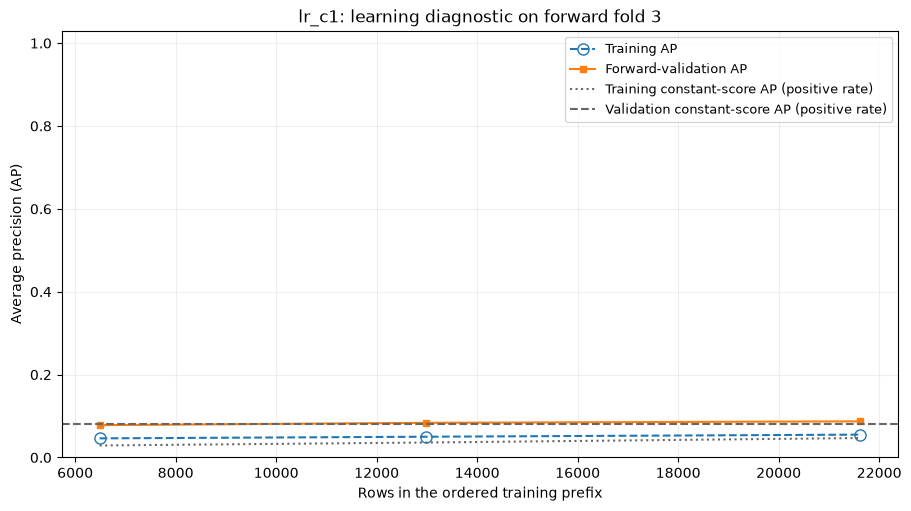

Explain the supported folds/sizes, AP alongside positive rates, and limitations in the notebook.


In [35]:
f_figure, f_axis = plt.subplots(figsize=(9, 5), layout="constrained")
if not curve_table.empty:
    f_axis.plot(curve_table["train_n"], curve_table["train_ap"], "o--", markersize=8,
                markerfacecolor="none", label="Training AP")
    f_axis.plot(curve_table["train_n"], curve_table["valid_ap"], "s-", markersize=4,
                label="Forward-validation AP")
    f_axis.plot(curve_table["train_n"], curve_table["train_rate"], ":", color="0.4",
                label="Training constant-score AP (positive rate)")
    f_axis.axhline(curve_table["valid_rate"].iloc[0], linestyle="--", color="0.4",
                   label="Validation constant-score AP (positive rate)")
    f_axis.set(xlabel="Rows in the ordered training prefix", ylabel="Average precision (AP)",
               ylim=(0, 1.03), title=f"lr_c1: learning diagnostic on forward fold {f_curve_fold}")
    f_axis.grid(alpha=0.2)
    f_axis.legend(fontsize=9)
else:
    f_axis.set_axis_off()
    f_axis.text(0.5, 0.5, "No supported learning-curve points.\n"
               "See fold_diagnostics.csv and learning_sizes.csv for class-support reasons.\n"
               "No learning-curve scores were calculated.", ha="center", va="center",
               transform=f_axis.transAxes, wrap=True)

f_figure.savefig(f_results / "figures/ordered_learning_curve.png", dpi=150)
plt.show()
plt.close(f_figure)
print("Explain the supported folds/sizes, AP alongside positive rates, and limitations in the notebook.")

In [36]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.calibration import CalibrationDisplay
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score
from sklearn.utils.validation import check_is_fitted

from helpers import FEATURES, evaluate_ranking, positive_scores, rank_customers

g_root = Path.cwd()
if not (g_root / "pyproject.toml").is_file():
    raise RuntimeError("Open the notebook from your campaign-mini project root.")
g_results = g_root / "results"
if any((g_results / name).exists() for name in ("final_access.json", "final_result.json")):
    raise RuntimeError("Final access was already recorded. Preserve the existing selection.")
assert list(X_train.columns) == list(X_dev.columns) == FEATURES
assert len(train_ids) == len(X_train) == len(y_train) > 0
assert len(dev_ids) == len(X_dev) == len(y_dev) > 0
assert train_ids.index.equals(X_train.index) and y_train.index.equals(X_train.index)
assert dev_ids.index.equals(X_dev.index) and y_dev.index.equals(X_dev.index)
assert set(y_train.unique()) == {0, 1} and y_dev.isin([0, 1]).all()
assert train_ids.is_unique and dev_ids.is_unique and train_ids.max() < dev_ids.min()
g_results.mkdir(parents=True, exist_ok=True)
(g_results / "figures").mkdir(parents=True, exist_ok=True)

In [37]:
g_family_order = {"prior": 0, "lr_c1": 1, "lr_c01": 1, "rf_d8": 2}
assert set(candidates) == set(g_family_order), "Use E's four declared attempts."
g_eligible_rows = []
for candidate_id, entry in candidates.items():
    record = entry["metrics"]
    if entry["status"] != "success" or record is None:
        continue
    if any(record[name] is None or not np.isfinite(record[name])
           for name in ("precision_at_budget", "ap")):
        continue
    if entry["pipeline"] is None or entry["run_id"] is None:
        raise RuntimeError(f"{candidate_id} lacks its original fitted object/run ID. Restore E.")
    check_is_fitted(entry["pipeline"])
    g_eligible_rows.append({
        "candidate_id": candidate_id, "run_id": entry["run_id"],
        "precision_at_budget": record["precision_at_budget"], "ap": record["ap"],
        "family_order": g_family_order[candidate_id],
    })

if not g_eligible_rows:
    raise RuntimeError("No eligible candidate: E needs a successful fitted model with defined precision and AP.")
selection_table = pd.DataFrame(g_eligible_rows).sort_values(
    ["precision_at_budget", "ap", "family_order", "candidate_id"],
    ascending=[False, False, True, True], ignore_index=True,
)
chosen_candidate_id = selection_table.loc[0, "candidate_id"]
g_chosen_entry = candidates[chosen_candidate_id]
chosen_pipeline = g_chosen_entry["pipeline"]
chosen_run_id = g_chosen_entry["run_id"]
chosen_probabilities = np.asarray(g_chosen_entry["dev_scores"], dtype=float)
np.testing.assert_allclose(positive_scores(chosen_pipeline, X_dev), chosen_probabilities,
                           rtol=1e-7, atol=1e-10)
g_dev_labels = pd.DataFrame({"record_id": dev_ids.to_numpy(), "y": y_dev.to_numpy()})
g_current_metrics = evaluate_ranking(dev_ids, chosen_probabilities, g_dev_labels, policy)
for name in ("n", "k", "positives", "precision_at_budget", "ap"):
    np.testing.assert_allclose(g_current_metrics[name], g_chosen_entry["metrics"][name])
selection_table.to_csv(g_results / "selection_candidates.csv", index=False)
display(selection_table)
print("Chosen existing candidate:", chosen_candidate_id, "run:", chosen_run_id)

,candidate_id,run_id,precision_at_budget,ap,family_order
0,rf_d8,c2846f42f8f144f0b500f96d4c23d56a,0.244733,0.182712,2
1,lr_c1,8786f26b22844c189acf1663ffe90a2b,0.231767,0.162378,1
2,lr_c01,6675bf04bb204594824df0ce32f2a6a3,0.222042,0.162821,1
3,prior,301cb87abae5472a9a26ab65bdf81cc8,0.087520,0.106507,0


Chosen existing candidate: rf_d8 run: c2846f42f8f144f0b500f96d4c23d56a


In [38]:
g_context = X_dev.copy()
g_context.insert(0, "record_id", dev_ids.to_numpy())
g_context["y"] = y_dev.to_numpy()
inspection = rank_customers(dev_ids, chosen_probabilities, policy).merge(
    g_context, on="record_id", how="left", validate="one_to_one", sort=False,
)
assert len(inspection) == len(X_dev) and inspection["y"].notna().all()
inspection["error_type"] = np.select([
    inspection["selected"] & inspection["y"].eq(0),
    ~inspection["selected"] & inspection["y"].eq(1),
    inspection["selected"] & inspection["y"].eq(1),
], ["FP", "FN", "TP"], default="TN")
inspection["selected_positive"] = inspection["selected"] & inspection["y"].eq(1)
assert int(inspection["selected"].sum()) == g_current_metrics["k"]
assert int(inspection["selected_positive"].sum()) == g_current_metrics["tp"]
error_examples = pd.concat([
    inspection.loc[inspection["error_type"].eq("FP")].head(5),
    inspection.loc[inspection["error_type"].eq("FN")].head(5),
], ignore_index=True)
inspection.to_csv(g_results / "dev_inspection.csv", index=False)
error_examples.to_csv(g_results / "error_examples.csv", index=False)
display(error_examples)
print("Inspect up to five FP and five FN rows; fewer is valid when fewer exist.")

,record_id,estimated_probability,rank,selected,age,previous,job,marital,education,housing,loan,poutcome,y,error_type,selected_positive
0,30390,0.370783,2,True,71.0,0.0,retired,divorced,basic.4y,yes,no,nonexistent,0,FP,False
1,29829,0.351942,4,True,69.0,0.0,retired,divorced,basic.4y,no,no,nonexistent,0,FP,False
2,30072,0.347227,8,True,85.0,0.0,retired,married,basic.4y,yes,no,nonexistent,0,FP,False
3,30078,0.347227,9,True,85.0,0.0,retired,married,basic.4y,yes,no,nonexistent,0,FP,False
4,30214,0.347227,10,True,83.0,0.0,retired,married,basic.4y,yes,no,nonexistent,0,FP,False
5,29345,0.077424,624,False,28.0,0.0,admin.,single,university.degree,no,no,nonexistent,1,FN,False
6,30310,0.076723,642,False,28.0,0.0,admin.,single,university.degree,no,yes,nonexistent,1,FN,False
7,29371,0.076608,645,False,60.0,0.0,retired,married,basic.4y,yes,no,nonexistent,1,FN,False
8,30397,0.076522,649,False,24.0,0.0,admin.,single,university.degree,yes,no,nonexistent,1,FN,False
9,32500,0.076411,653,False,25.0,1.0,admin.,single,high.school,no,no,failure,1,FN,False


Inspect up to five FP and five FN rows; fewer is valid when fewer exist.


In [39]:
inspection["job_group"] = np.where(
    inspection["job"].fillna("unknown").eq("unknown"), "unknown_or_missing", "reported_value",
)
inspection["poutcome_group"] = inspection["poutcome"].fillna("<missing>")
g_group_tables = []
for column in ("job_group", "poutcome_group"):
    summary = inspection.groupby(column, dropna=False).agg(
        n=("y", "size"), positives=("y", "sum"),
        selected_n=("selected", "sum"), tp=("selected_positive", "sum"),
    ).reset_index().rename(columns={column: "group"})
    summary.insert(0, "group_by", column)
    summary["positive_rate"] = summary["positives"] / summary["n"]
    summary["selected_fraction"] = summary["selected_n"] / summary["n"]
    summary["precision_among_selected"] = summary["tp"] / summary["selected_n"].replace(0, np.nan)
    summary["recall_among_positives"] = summary["tp"] / summary["positives"].replace(0, np.nan)
    summary["undefined_reason"] = np.select([
        summary["selected_n"].eq(0) & summary["positives"].eq(0),
        summary["selected_n"].eq(0), summary["positives"].eq(0),
    ], ["no selected rows; no positives", "no selected rows", "no positives"], default="")
    g_group_tables.append(summary)
group_table = pd.concat(g_group_tables, ignore_index=True)
group_table.to_csv(g_results / "development_groups.csv", index=False)
display(group_table)

,group_by,group,n,positives,selected_n,tp,positive_rate,selected_fraction,precision_among_selected,recall_among_positives,undefined_reason
0,job_group,reported_value,6159,656,611,150,0.106511,0.099204,0.245499,0.228659,
1,job_group,unknown_or_missing,19,2,6,1,0.105263,0.315789,0.166667,0.500000,
2,poutcome_group,failure,1808,106,201,19,0.058628,0.111173,0.094527,0.179245,
3,poutcome_group,nonexistent,4218,485,269,68,0.114983,0.063774,0.252788,0.140206,
4,poutcome_group,success,152,67,147,64,0.440789,0.967105,0.435374,0.955224,


In [40]:
g_ap_rows = []
for candidate_id in ("lr_c1", "lr_c01", "rf_d8"):
    entry = candidates[candidate_id]
    if entry["status"] != "success":
        continue
    g_train_scores = positive_scores(entry["pipeline"], X_train)
    g_train_ap = float(average_precision_score(y_train, g_train_scores))
    g_ap_rows.append({
        "candidate_id": candidate_id, "train_n": len(y_train), "dev_n": len(y_dev),
        "train_positive_rate": float(y_train.mean()), "dev_positive_rate": float(y_dev.mean()),
        "train_ap": g_train_ap, "dev_ap": entry["metrics"]["ap"],
        "train_minus_dev_ap": g_train_ap - entry["metrics"]["ap"],
    })
ap_comparison = pd.DataFrame(g_ap_rows, columns=[
    "candidate_id", "train_n", "dev_n", "train_positive_rate", "dev_positive_rate",
    "train_ap", "dev_ap", "train_minus_dev_ap",
])
ap_comparison.to_csv(g_results / "train_dev_ap.csv", index=False)
display(ap_comparison)
if ap_comparison.empty:
    print("No successful learned models: report this limitation; the prior may still be selected.")

,candidate_id,train_n,dev_n,train_positive_rate,dev_positive_rate,train_ap,dev_ap,train_minus_dev_ap
0,lr_c1,28831,6178,0.055704,0.106507,0.073875,0.162378,-0.088503
1,lr_c01,28831,6178,0.055704,0.106507,0.073440,0.162821,-0.089381
2,rf_d8,28831,6178,0.055704,0.106507,0.114503,0.182712,-0.068210


,probability_bin,n,mean_probability,observed_positive_rate
0,"(-0.001, 0.2]",6123,0.059439,0.104361
1,"(0.2, 0.4]",55,0.290006,0.345455
2,"(0.4, 0.6]",0,NaN,NaN
3,"(0.6, 0.8]",0,NaN,NaN
4,"(0.8, 1.0]",0,NaN,NaN


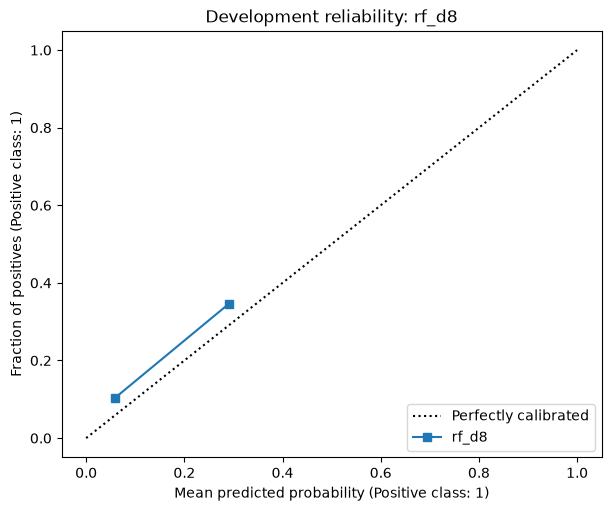

In [41]:
g_calibration_rows = pd.DataFrame({"probability": chosen_probabilities, "y": y_dev.to_numpy()})
g_calibration_rows["probability_bin"] = pd.cut(
    g_calibration_rows["probability"], bins=np.linspace(0, 1, 6), include_lowest=True, right=True,
)
calibration_table = g_calibration_rows.groupby("probability_bin", observed=False).agg(
    n=("y", "size"), mean_probability=("probability", "mean"), observed_positive_rate=("y", "mean"),
).reset_index()
assert calibration_table["n"].sum() == len(y_dev)
calibration_table.to_csv(g_results / "calibration_bins.csv", index=False)
display(calibration_table)
g_calibration_figure, g_calibration_axis = plt.subplots(figsize=(6, 5), layout="constrained")
calibration_display = CalibrationDisplay.from_predictions(
    y_dev, chosen_probabilities, n_bins=5, strategy="uniform", pos_label=1,
    name=chosen_candidate_id, ax=g_calibration_axis,
)
g_calibration_axis.set_title(f"Development reliability: {chosen_candidate_id}")
g_calibration_figure.savefig(g_results / "figures/development_calibration.png", dpi=150)
plt.show()
plt.close(g_calibration_figure)

In [42]:
g_permutation = permutation_importance(
    chosen_pipeline, X_dev, y_dev, scoring="average_precision",
    n_repeats=3, random_state=42, n_jobs=1,
)
importance_table = pd.DataFrame({
    "feature": FEATURES,
    "mean_ap_decrease": g_permutation.importances_mean,
    "std_ap_decrease": g_permutation.importances_std,
}).sort_values("mean_ap_decrease", ascending=False, ignore_index=True)
importance_table.to_csv(g_results / "permutation_importance.csv", index=False)
display(importance_table)
print("Write observed findings, limitations and one future experiment. Do not run an expanded search.")


,feature,mean_ap_decrease,std_ap_decrease
0,age,0.032182,0.001599
1,poutcome,0.025530,0.001069
2,job,0.009479,0.003178
3,education,0.003459,0.001941
4,housing,0.000276,0.001126
5,loan,-0.000279,0.000513
6,previous,-0.001871,0.001230
7,marital,-0.002542,0.004010


Write observed findings, limitations and one future experiment. Do not run an expanded search.
